In [1]:
# T2 is when P0 is down to 0.5 + P0(intial)/e since it ends at 0.5 where it is totally mixed.
# I will use the long pulse since T2 only occurs when the drive is on.
import numpy as np
from scipy.sparse import linalg as sla
import matplotlib.pyplot as plt
from myfunctions import powell_search, gaussian, rk4solve
from part2 import H_number, H_time
from part3 import Lindblad
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

#create the hamilton and the initial density matrix
##
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz 50x smaller than E_j
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
t1, t2= 200, 150 # the relaxation and dephasing times in ns
gamma= 1 * np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
T_g = 500 # gate time in ns
dT_g=0.005 # stepsize
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix
mu = T_g/2 # the amplitude is at its maximum at half of the gate time
sigma = T_g/6 # make sure it is close to zero in the start and end

H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues  and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0]  # Taken from part 4.
A= U.T @ np.diag(N) @ U #the coupling term between the different states
omega= E_c/20# the amplitude of the drive must be smaller than E_c  # the amplitude of the drive in rad/ns taken from part 4

def f(t,rho): 
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)
t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)

In [38]:
P0 = C_L[:, 0, 0].real # the population of the ground state

def T2_fit(t,b,T2, rabi):
    return b + 0.5 * np.exp(-t/T2) * np.cos(rabi * t) # since the P0= 1-P1
b_guess = 0.5 # the initial guess for the offset of the decaying exponential function
rabi_guess = 0.0850 # The rabi frequency founnd in part5_Rabi.py

peaks, _ = find_peaks(P0, prominence=0.05)            # index for peaks in the data
T2_guess = 1 / (np.log((P0[peaks[0]]-0.5)/(P0[peaks[1]]-0.5))/(t_L[peaks[1]]-t_L[peaks[0]])) # the initial guess for T2 using the first two peaks
t1_fit =200.83 # ns from part5_T1.py

In [39]:
p0 = [b_guess, T2_guess, rabi_guess] # the initial guess for the parameters
par, cov = curve_fit(T2_fit,t_L,P0,p0=p0) # fit the data to the decaying exponential function

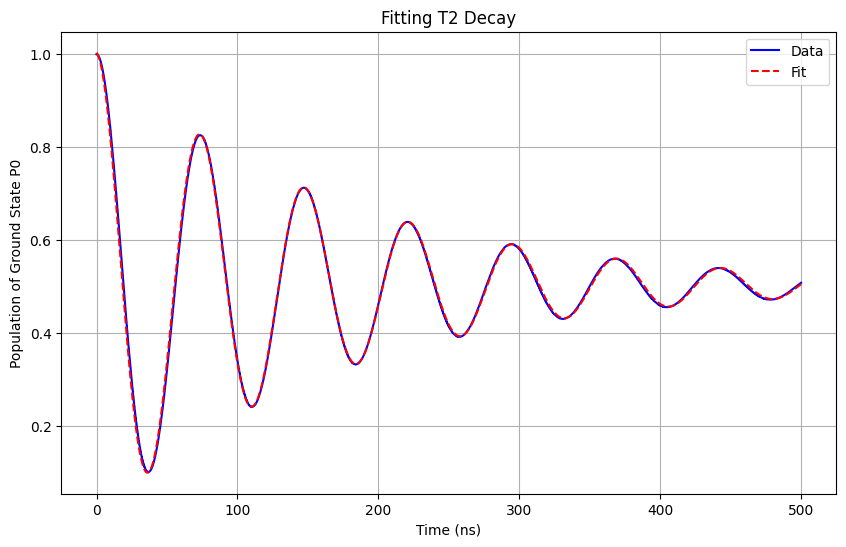

In [42]:
plt.figure(figsize=(10,6))
plt.plot(t_L, P0, label='Data', color='blue')
plt.plot(t_L, T2_fit(t_L, *par), label='Fit', color='red', linestyle='--')
plt.xlabel('Time (ns)')
plt.ylabel('Population of Ground State P0')
plt.title('Fitting T2 Decay')
plt.legend()
plt.grid()
plt.show()

In [43]:
t2_fit = T2_guess * t1_fit / (2*t1_fit - T2_guess) # the initial guess for T2 using the first two peaks and the fitted value of T1


In [44]:
t2_fit

np.float64(151.53445254722564)

In [45]:
t2_fit = par[1] * t1_fit / (2*t1_fit - par[1]) # t2_fit